In [1]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# 오류 발생시
sklearn.set_config(display="text")

## 환경 설정

In [2]:
base_path = r"C:\kdt_0900_osg\ml\resource\dataset"
car_path = os.path.join(base_path, "f1_split")

In [3]:
load_dotenv()

print(os.environ["KAGGLE_API_TOKEN"][:7])

KGAT_99


In [13]:
import os
from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()

output_dir = r"C:\kdt_0900_osg\ml\resource\dataset"
os.makedirs(output_dir, exist_ok=True)

api.dataset_download_files(
    "vesuvius13/formula-one-cars",
    path=output_dir,
    unzip=True
)

print("다운로드 완료!")

Dataset URL: https://www.kaggle.com/datasets/vesuvius13/formula-one-cars
다운로드 완료!


## 데이터 로드 & 증강 파이프라인 구성

In [4]:
# 80:20 분리
train_path = os.path.join(base_path, "f1_split", "train")
val_path = os.path.join(base_path, "f1_split", "test")

In [5]:
# 이미지 크기 224×224 및 Train 전용 증강
from torchvision import transforms

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

In [6]:
# ImageFolder로 데이터셋 불러오기
train_dataset = ImageFolder(train_path, transform=train_transform)
val_dataset = ImageFolder(val_path, transform=val_transform)

In [7]:
print(len(train_dataset), len(val_dataset))

1096 276


In [8]:
train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=2)
val_dataloader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=2)

In [9]:
# DataLoader 생성 (batch_size=32)
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

In [10]:
# 클래스 수·라벨 매핑·이미지 수 및 실제 배치 확인
print("클래스 수:", len(train_dataset.classes))
print("클래스 목록:", train_dataset.classes)
print("라벨 매핑:", train_dataset.class_to_idx)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))

images, labels = next(iter(train_loader))

print("이미지 shape:", images.shape)
print("라벨 shape:", labels.shape)

클래스 수: 4
클래스 목록: ['Ferrari F1 car', 'McLaren F1 car', 'Mercedes F1 car', 'Red Bull Racing F1 car']
라벨 매핑: {'Ferrari F1 car': 0, 'McLaren F1 car': 1, 'Mercedes F1 car': 2, 'Red Bull Racing F1 car': 3}
Train: 1096
Validation: 276
이미지 shape: torch.Size([32, 3, 224, 224])
라벨 shape: torch.Size([32])


In [49]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: cpu


In [50]:
model1 = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

### 프리징

In [51]:
for param in model1.parameters():
    param.requires_grad = False

In [52]:
model1 = nn.Sequential(
    model1.features,
    nn.AdaptiveAvgPool2d((1, 1)),
    nn.Flatten(),
    nn.Dropout(0.2),
    nn.Linear(1280, 256),
    nn.BatchNorm1d(256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, 4)
)

model1 = model1.to(device)

In [58]:
def train_one_epoch_multiclass(model, dataloader, criterion, optimizer, device="cpu"):
    model.train()
    model[0].eval()
    sum_losses = 0.0
    sum_accs = 0.0

    for i, (X_batch, y_batch) in enumerate(dataloader, 1):
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        batch_loss = 0.0
        
        # 학습
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()

        batch_loss += loss.item()
        sum_losses += batch_loss

        # 다중 클래스의 정확도 계산
        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_accs += acc

        if i % 20 == 0:
            print(f"[Batch {i}/{len(dataloader)}] Batch Loss: {batch_loss:.4f}, Batch Accuracy: {acc:.2f}%")

    avg_loss = sum_losses / len(dataloader)
    avg_acc = sum_accs / len(dataloader)

    return avg_loss, avg_acc

In [59]:
@torch.no_grad()
def evaluate_multiclass(model, dataloader, criterion, device="cpu"):
    model.eval()
    sum_losses = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)

        sum_losses += loss.item() * len(y_batch)

        # 다중 클래스 정확도 계산
        y_pred_index = y_pred.argmax(dim=1)
        correct += (y_batch == y_pred_index).sum().item()
        total += len(y_batch)

    avg_loss = sum_losses / total
    avg_acc = correct / total * 100

    return avg_loss, avg_acc

In [60]:
def train_model_multiclass(model, model_name, train_loader, val_loader, criterion, optimizer, epochs, device, save_base_dir):
    save_dir = os.path.join(save_base_dir, model_name)
    os.makedirs(save_dir, exist_ok=True)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc = -1.0

    # 학습
    print(f"========================={model_name} 학습 시작 ============================")
    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch_multiclass(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate_multiclass(model, val_loader, criterion, device)

        print(f"[Epoch: {epoch + 1}] | Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
        print(f"[Epoch: {epoch + 1}] | Validation Loss: {val_loss:.4f} | Validation Accuracy: {val_acc:.2f}%")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), os.path.join(save_dir, "best_model.pth"))

    torch.save(model.state_dict(), os.path.join(save_dir, f"last_model_{epochs}.pth"))
    print(f"========================={model_name} 학습 종료 ============================")
    return history

In [61]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model1[3:].parameters(), lr=0.001)

In [63]:
save_base_dir = os.path.join(base_path, "weights")

history1 = train_model_multiclass(
    model=model1,
    model_name="MobileNetV2_F1",
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=10,
    device=device,
    save_base_dir=save_base_dir
)

=========================MobileNetV2_F1 학습 시작 ============================
[Batch 20/35] Batch Loss: 0.0604, Batch Accuracy: 96.88%
[Epoch: 1] | Train Loss: 0.1363 | Train Accuracy: 95.18%
[Epoch: 1] | Validation Loss: 0.3742 | Validation Accuracy: 88.41%
[Batch 20/35] Batch Loss: 0.1932, Batch Accuracy: 93.75%
[Epoch: 2] | Train Loss: 0.1267 | Train Accuracy: 96.07%
[Epoch: 2] | Validation Loss: 0.3770 | Validation Accuracy: 89.86%
[Batch 20/35] Batch Loss: 0.1669, Batch Accuracy: 93.75%
[Epoch: 3] | Train Loss: 0.1390 | Train Accuracy: 95.98%
[Epoch: 3] | Validation Loss: 0.3967 | Validation Accuracy: 88.04%
[Batch 20/35] Batch Loss: 0.0648, Batch Accuracy: 96.88%
[Epoch: 4] | Train Loss: 0.1276 | Train Accuracy: 95.00%
[Epoch: 4] | Validation Loss: 0.3650 | Validation Accuracy: 90.22%
[Batch 20/35] Batch Loss: 0.1277, Batch Accuracy: 96.88%
[Epoch: 5] | Train Loss: 0.1408 | Train Accuracy: 95.18%
[Epoch: 5] | Validation Loss: 0.3804 | Validation Accuracy: 89.49%
[Batch 20/35] Batch 

In [64]:
best_path = os.path.join(
    save_base_dir,
    "MobileNetV2_F1",
    "best_model.pth"
)

print("Best 모델 저장 여부:", os.path.exists(best_path))

Best 모델 저장 여부: True


In [71]:
best_model_path = os.path.join(save_base_dir, "MobileNetV2_F1", "best_model.pth")
best_model_path

'C:\\kdt_0900_osg\\ml\\resource\\dataset\\weights\\MobileNetV2_F1\\best_model.pth'

In [72]:
model1.load_state_dict(torch.load(best_model_path, map_location=device, weights_only=True))
model1 = model1.to(device)

In [73]:
# 평가 모드
model1.eval()

# 검증 데이터로 평가
val_loss, val_acc = evaluate_multiclass(
    model=model1,
    dataloader=val_loader,
    criterion=criterion,
    device=device
)

print("최종 모델 평가")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_acc:.2f}%")

최종 모델 평가
Validation Loss: 0.3552
Validation Accuracy: 92.03%


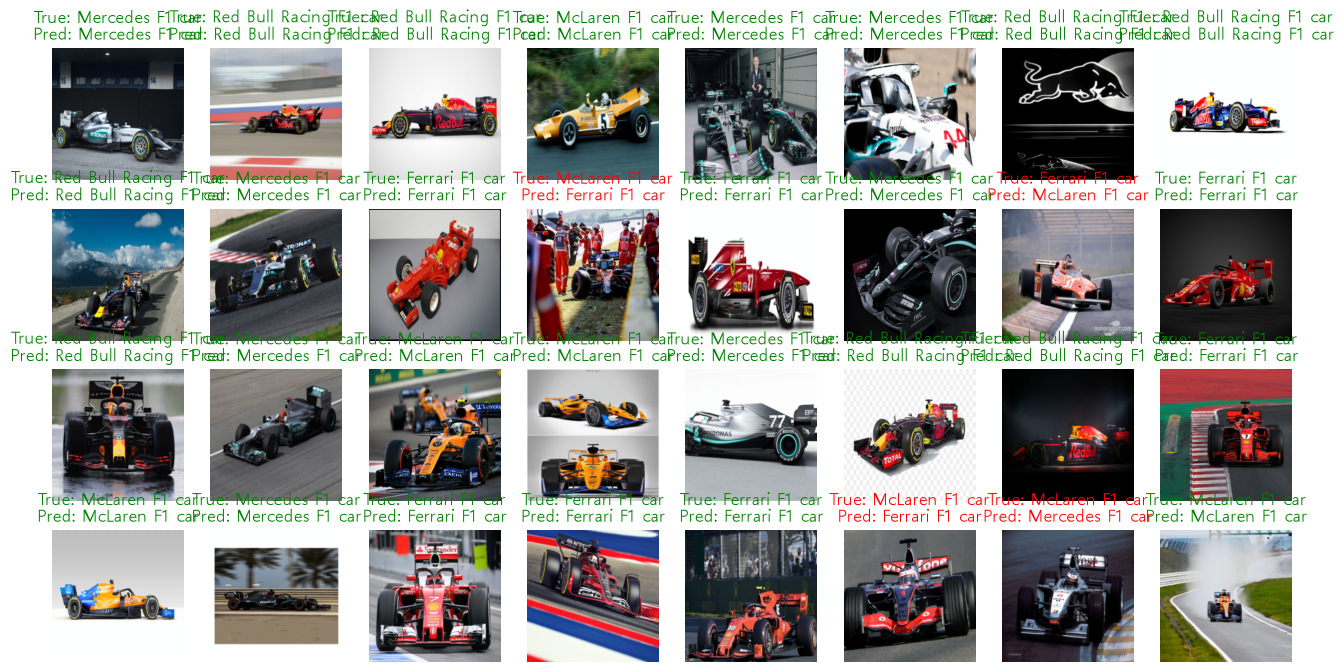

In [85]:
model1.eval()
imgs_device = imgs.to(device)

with torch.no_grad():
    preds = model1(imgs_device)
    pred_labels = preds.argmax(dim=1).cpu()

fig, axes = plt.subplots(4, 8, figsize=(16, 8))

mean = np.array(mean)
std = np.array(std)

for ax, img, label, pred in zip(axes.flatten(), imgs, labels, pred_labels):
    img_np = img.permute(1, 2, 0).numpy()
    img_np = np.clip(img_np * std + mean, 0, 1)
    true_label = int(label.item())
    pred_label = int(pred.item())
    color = "green" if true_label == pred_label else "red"
    ax.imshow(img_np)
    ax.set_title(f"True: {class_dict[true_label]}\nPred: {class_dict[pred_label]}", color=color)
    ax.axis("off")

plt.show()

In [86]:
model1.eval()
imgs_device = imgs.to(device)

with torch.no_grad():
    preds = model1(imgs_device)
    pred_labels = preds.argmax(dim=1).cpu()

incorrect_samples = []
incorrect_mask = (pred_labels != labels)

if incorrect_mask.any():
    for img, label, pred in zip(imgs[incorrect_mask], labels[incorrect_mask], pred_labels[incorrect_mask]):
        incorrect_samples.append({
            "img": img,
            "true_label": label.item(),
            "pred_label": pred.item()
        })

print(incorrect_samples)

[{'img': tensor([[[ 1.9064,  1.9235,  1.9578,  ...,  0.6906,  0.9303,  1.2385],
         [ 1.9235,  1.9407,  1.9920,  ...,  0.6734,  0.6734,  1.1529],
         [ 1.9578,  1.9578,  2.0263,  ...,  0.9132,  0.6049,  1.0159],
         ...,
         [-0.5082, -0.3712, -0.2684,  ..., -0.2342, -0.2513, -0.2856],
         [-0.3712, -0.2684, -0.1657,  ..., -0.1657, -0.1828, -0.2684],
         [-0.2684, -0.1657, -0.0458,  ..., -0.1314, -0.1657, -0.2171]],

        [[ 1.0280,  1.0630,  1.1506,  ...,  1.1506,  1.3431,  1.6933],
         [ 1.0455,  1.0980,  1.2031,  ...,  1.0980,  1.0805,  1.5532],
         [ 1.0805,  1.0980,  1.2556,  ...,  1.3782,  1.0630,  1.4307],
         ...,
         [-0.6702, -0.5476, -0.4601,  ..., -0.0224, -0.0399, -0.0924],
         [-0.5476, -0.4251, -0.3375,  ...,  0.0651,  0.0301,  0.0126],
         [-0.4251, -0.3025, -0.2500,  ...,  0.1001,  0.0651,  0.0826]],

        [[ 1.3851,  1.4200,  1.4897,  ...,  1.3502,  1.5594,  1.9080],
         [ 1.4025,  1.4374,  1.5245,

In [75]:
y_true = []
y_pred = []

model1.eval()

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        X_batch = X_batch.to(device)

        outputs = model1(X_batch)
        predictions = outputs.argmax(dim=1)

        y_true.extend(y_batch.tolist())
        y_pred.extend(predictions.cpu().tolist())

In [76]:
f1 = f1_score(y_true, y_pred, average="macro")

print(f"Macro F1-score: {f1:.4f}")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(val_dataset.classes))),
    target_names=val_dataset.classes,
    zero_division=0
))

Macro F1-score: 0.9200
                        precision    recall  f1-score   support

        Ferrari F1 car       0.95      0.96      0.95        73
        McLaren F1 car       0.93      0.85      0.89        73
       Mercedes F1 car       0.86      0.97      0.91        64
Red Bull Racing F1 car       0.95      0.91      0.93        66

              accuracy                           0.92       276
             macro avg       0.92      0.92      0.92       276
          weighted avg       0.92      0.92      0.92       276

